# 00 · Análisis exploratorio
Objetivo: entender **qué cambió respecto a la Parte 1** (multilingüe + sentimiento indirecto) y cómo difieren train y eval.
Corre en CPU en segundos.

In [1]:
import sys, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '../src')
from lang_detect import detect_lang
train = pd.read_csv('../data/train.csv'); ev = pd.read_csv('../data/eval.csv')
for d in (train, ev): d['lang'] = d.text.map(detect_lang); d['n_chars'] = d.text.str.len()
LANGS = ['es', 'en', 'pt', 'fr', 'es-en']; LABELS = ['negativo', 'neutral', 'positivo']
print(train.shape, ev.shape)

(20466, 5) (6781, 4)


## Balance de clases

In [2]:
display(train.label.value_counts().to_frame('n').assign(pct=lambda d: (d.n / d.n.sum() * 100).round(1)))

,n,pct
label,,
positivo,7486,36.6
negativo,7381,36.1
neutral,5599,27.4


## Idiomas: cambio de distribución train → eval
El enunciado advierte que eval no sigue la distribución de train. El detector de idioma (stopwords, `src/lang_detect.py`) confirma
que **eval tiene menos español y más inglés/portugués/francés** → un modelo bueno solo en español pierde puntos.

,train %,eval %,eval/train
lang,,,
es,66.7,60.4,0.91
en,11.5,13.7,1.19
pt,11.3,13.5,1.19
fr,10.2,11.8,1.16
es-en,0.4,0.6,1.50


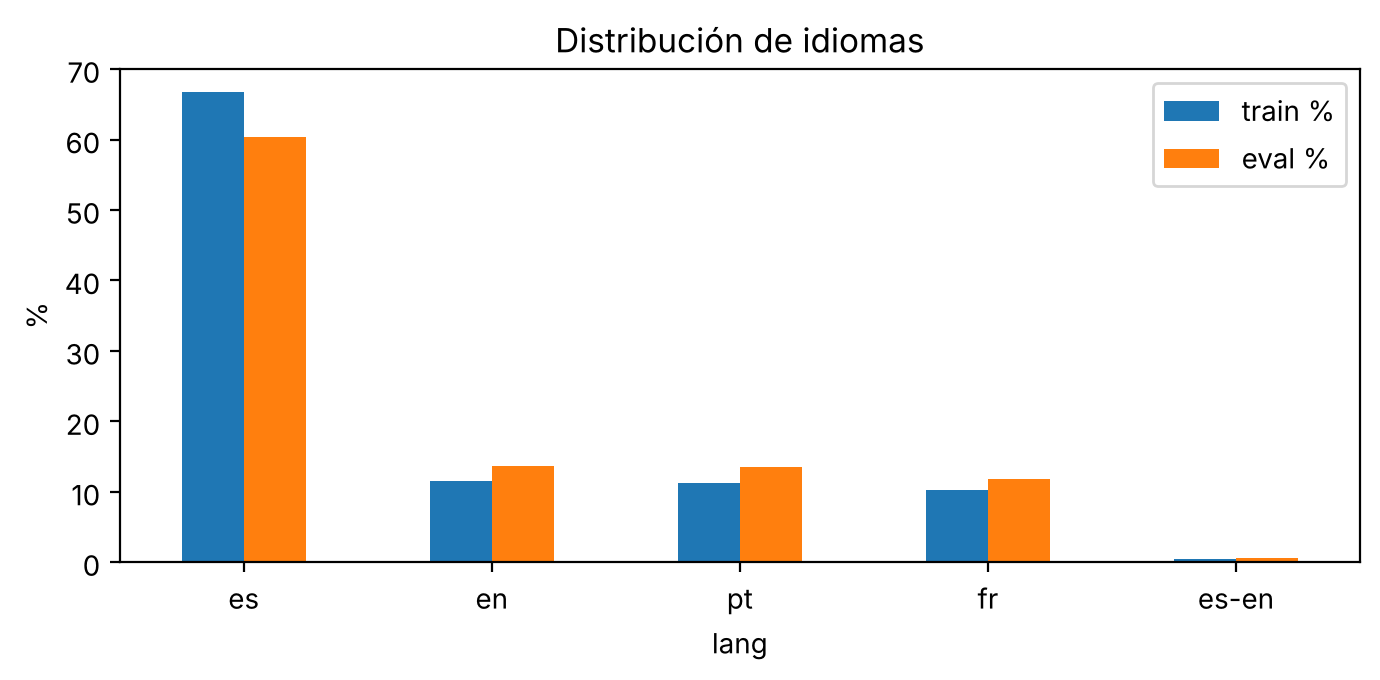

In [3]:
shift = pd.DataFrame({'train %': train.lang.value_counts(normalize=True), 'eval %': ev.lang.value_counts(normalize=True)}).reindex(LANGS).mul(100).round(1)
shift['eval/train'] = (shift['eval %'] / shift['train %']).round(2)
display(shift)
ax = shift[['train %', 'eval %']].plot.bar(rot=0, figsize=(7, 3.5), title='Distribución de idiomas'); ax.set_ylabel('%'); plt.tight_layout(); plt.show()

In [4]:
display(pd.crosstab(train.lang, train.label, normalize='index').reindex(LANGS).round(3))

label,negativo,neutral,positivo
lang,,,
es,0.369,0.263,0.368
en,0.329,0.319,0.351
pt,0.347,0.295,0.357
fr,0.353,0.275,0.372
es-en,0.432,0.014,0.554


## Longitud de las reseñas

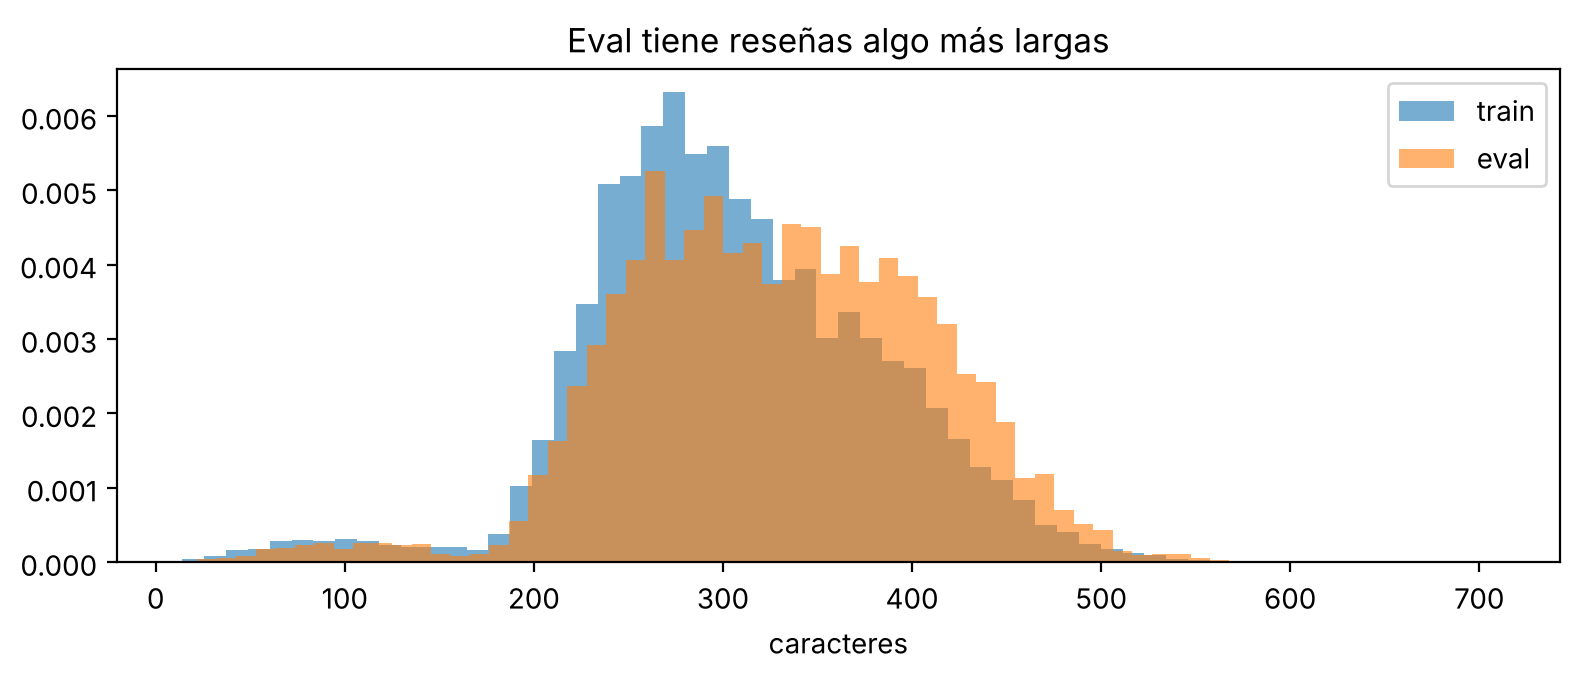

,train,eval
count,20466.0,6781.0
mean,305.0,327.0
std,78.0,81.0
min,14.0,22.0
25%,254.0,269.0
50%,298.0,327.0
75%,356.0,387.0
max,708.0,640.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.n_chars, bins=60, alpha=.6, density=True, label='train'); ax.hist(ev.n_chars, bins=60, alpha=.6, density=True, label='eval')
ax.set_xlabel('caracteres'); ax.legend(); ax.set_title('Eval tiene reseñas algo más largas'); plt.tight_layout(); plt.show()
display(pd.DataFrame({'train': train.n_chars.describe(), 'eval': ev.n_chars.describe()}).round(0))

## Ejemplos por idioma y fenómenos difíciles
Muchas reseñas comparten una plantilla (envío, empaque, uso) y el sentimiento está en **una o dos oraciones**, a veces con
contraste o mezclando aspectos positivos y negativos.

In [6]:
for lg in ['es', 'en', 'pt', 'fr', 'es-en']:
    for r in train[train.lang == lg].sample(2, random_state=1).itertuples():
        print(f'[{lg} · {r.label}] {r.text[:260]}\n')

[es · positivo] Ya llevo varias semanas usándolo, así que lo he probado bastante a fondo. Lo compré a inicios de mes y llegó sin problema. Sobre el cable, pues cada quien saca sus conclusiones. Yo volvería a contratar el servicio sin pensarlo.

[es · negativo] Lo compré a inicios de año en una tienda online y llegó en tres días. Lo pruebo casi todos los días desde hace un par de meses, más que nada en las tardes después del trabajo. El sistema de sonido está muy por debajo de la media.

[en · negativo] I ordered it on a Tuesday and it arrived by Friday, in its sealed box. I bought it because I was redoing a few things in the living room. The remote control was a purchase mistake. Other than that, the quality is exactly what I was looking for. It has a bit of

[en · positivo] I bought this mid-year and I've been using it at the office almost every day. The package arrived at my house in four days, no issues. I asked my brother to help me set it up because he knows more about these gadge

In [7]:
PHEN = {'negación': r"\b(?:no|not|nunca|never|pas|jamais|não|nem|n't)\b",
        'contraste': r"\b(?:pero|but|however|sin embargo|aunque|mais|mas|porém|embora|cependant)\b",
        'devolución': r"\b(?:devolví|devolvi|returned|rendu|reembolso|refund)\b"}
display(pd.DataFrame({k: [train.text.str.contains(p, case=False).mean(), ev.text.str.contains(p, case=False).mean()] for k, p in PHEN.items()},
                     index=['train', 'eval']).mul(100).round(1).rename_axis('% reseñas con...'))

,negación,contraste,devolución
% reseñas con...,,,
train,41.7,21.3,1.7
eval,48.7,29.8,3.6


## Conclusiones para el diseño
1. **Modelo multilingüe** (XLM-R) en vez de uno solo-español (BETO, que usamos en el proyecto anterior).
2. **Aumentar en/pt/fr** traduciendo reseñas en español → compensa el cambio de distribución.
3. **Code-switching** casi no aparece en train → se generan ejemplos sintéticos.
4. Las reseñas caben en ≤ 256 tokens → `MAX_LEN=256` sin truncar.